In [1]:
# Shim: notebook tidak punya __file__.
import os
__file__ = os.path.abspath("mnist_mlp.ipynb")

# # Tugas Praktikum — Klasifikasi MNIST dengan JST (Keras)
#
# Model: `Flatten(28x28) -> Dense(h1, relu) -> Dense(h2, relu) -> Dense(10, softmax)`.
# Data: 60.000 latih + 10.000 uji, piksel dinormalisasi ke 0-1, label one-hot.
# Eksperimen: variasi neuron (256/128 vs 64/32), tambah 1 hidden layer, Sigmoid vs ReLU —
# dibandingkan akurasi **dan** waktu latih. Semua dilatih 5 epoch, batch 128, seed 42.

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from pathlib import Path
from tensorflow.keras.datasets import mnist

HERE = Path(__file__).resolve().parent
OUT = HERE / "output"
OUT.mkdir(exist_ok=True)
SEED = 42
tf.keras.utils.set_random_seed(SEED)
np.random.seed(SEED)
EPOCHS, BATCH = 5, 128
print("tf", tf.__version__)

tf 2.15.1


# ## 1. Load dan siapkan dataset

latih: (60000, 28, 28) | uji: (10000, 28, 28)
kelas: [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]


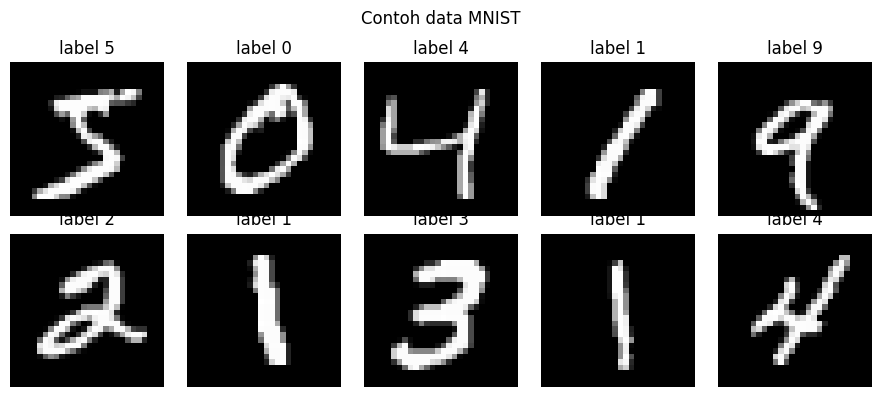

In [3]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()
X_train = X_train / 255.0
X_test = X_test / 255.0
y_train_c = tf.keras.utils.to_categorical(y_train, 10)
y_test_c = tf.keras.utils.to_categorical(y_test, 10)
print("latih:", X_train.shape, "| uji:", X_test.shape)
print("kelas:", np.bincount(y_train))

fig, axes = plt.subplots(2, 5, figsize=(9, 4))
for ax, i in zip(axes.ravel(), range(10)):
    ax.imshow(X_train[i], cmap="gray")
    ax.set_title(f"label {y_train[i]}"); ax.axis("off")
fig.suptitle("Contoh data MNIST")
fig.tight_layout(); fig.savefig(OUT / "01_contoh_digit.png", dpi=120)

# ## 2. Model dasar 2 hidden layer (256 & 128 neuron, ReLU)

In [4]:
def buat_model(hidden=(256, 128), act="relu"):
    layers = [tf.keras.Input(shape=(28, 28)), tf.keras.layers.Flatten()]
    for h in hidden:
        layers.append(tf.keras.layers.Dense(h, activation=act))
    layers.append(tf.keras.layers.Dense(10, activation="softmax"))
    m = tf.keras.Sequential(layers)
    m.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
    return m


tf.keras.utils.set_random_seed(SEED)
model = buat_model()
model.summary()
h = model.fit(X_train, y_train_c, epochs=EPOCHS, batch_size=BATCH,
              validation_split=0.1, verbose=2)
loss, acc = model.evaluate(X_test, y_test_c, verbose=0)
print(f"\nAkurasi pada data uji: {acc:.4f} (loss {loss:.4f})")

Model: "sequential"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 flatten (Flatten)           (None, 784)               0         


 dense (Dense)               (None, 256)               200960    


 dense_1 (Dense)             (None, 128)               32896     


... (12 outputs left out)

422/422 - 2s - loss: 0.0523 - accuracy: 0.9838 - val_loss: 0.0787 - val_accuracy: 0.9773 - 2s/epoch - 5ms/step


Epoch 5/5


422/422 - 2s - loss: 0.0379 - accuracy: 0.9886 - val_loss: 0.0779 - val_accuracy: 0.9778 - 2s/epoch - 5ms/step



Akurasi pada data uji: 0.9771 (loss 0.0752)


# ## 3. Eksperimen: neuron, kedalaman, dan fungsi aktivasi
#
# | # | konfigurasi | keterangan |
# |---|---|---|
# | 1 | 256-128 relu | model dasar (2 hidden layer) |
# | 2 | 64-32 relu | neuron diperkecil |
# | 3 | 256-128-64 relu | ditambah 1 hidden layer |
# | 4 | 256-128 sigmoid | aktivasi Sigmoid vs ReLU |

256-128 relu           akurasi_uji=0.9771 loss=0.0752 waktu=12.0s


64-32 relu             akurasi_uji=0.9666 loss=0.1092 waktu=7.4s


256-128-64 relu        akurasi_uji=0.9779 loss=0.0739 waktu=12.3s


256-128 sigmoid        akurasi_uji=0.9639 loss=0.1215 waktu=12.8s

     eksperimen  akurasi_uji  loss_uji  akurasi_val  waktu_latih_detik
   256-128 relu       0.9771    0.0752       0.9778            11.9580
     64-32 relu       0.9666    0.1092       0.9728             7.4118
256-128-64 relu       0.9779    0.0739       0.9790            12.2854
256-128 sigmoid       0.9639    0.1215       0.9708            12.8275


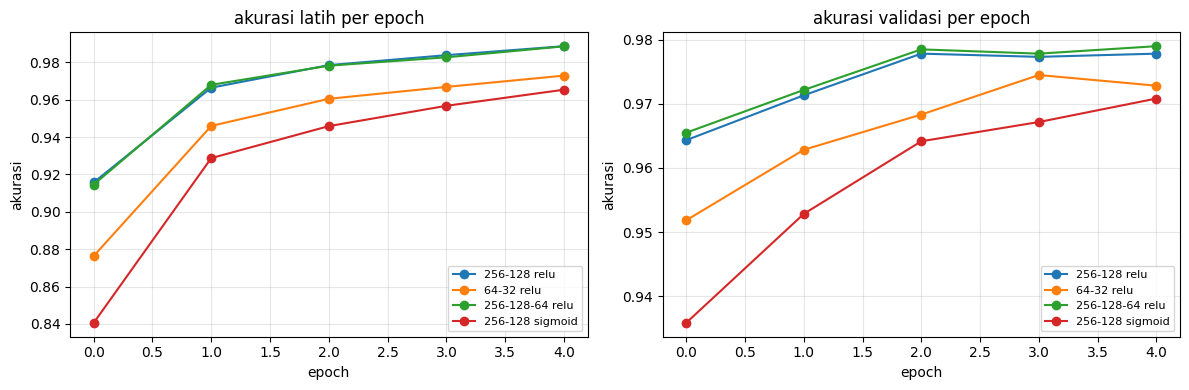

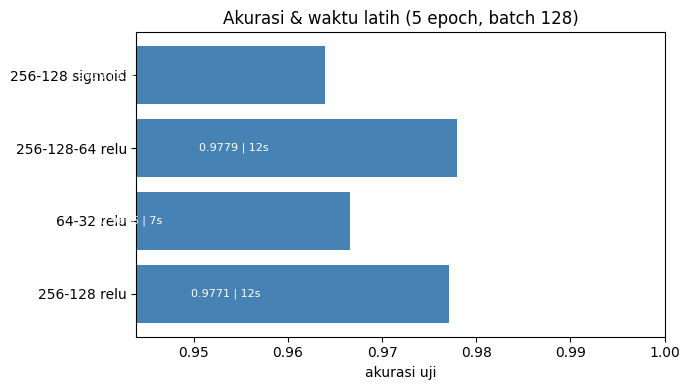

In [5]:
def latih_ukur(nama, hidden, act="relu"):
    tf.keras.utils.set_random_seed(SEED)
    m = buat_model(hidden=hidden, act=act)
    t0 = time.perf_counter()
    hist = m.fit(X_train, y_train_c, epochs=EPOCHS, batch_size=BATCH,
                 validation_split=0.1, verbose=0)
    waktu = time.perf_counter() - t0
    l, a = m.evaluate(X_test, y_test_c, verbose=0)
    print(f"{nama:22s} akurasi_uji={a:.4f} loss={l:.4f} waktu={waktu:.1f}s")
    return dict(eksperimen=nama, hidden=str(hidden), aktifasi=act,
                akurasi_uji=a, loss_uji=l, waktu_latih_detik=waktu,
                akurasi_val=hist.history['val_accuracy'][-1]), hist


baris, riwayat = [], {}
for nama, hidden, act in [("256-128 relu", (256, 128), "relu"),
                          ("64-32 relu", (64, 32), "relu"),
                          ("256-128-64 relu", (256, 128, 64), "relu"),
                          ("256-128 sigmoid", (256, 128), "sigmoid")]:
    r, hist = latih_ukur(nama, hidden, act)
    baris.append(r); riwayat[nama] = hist.history

df = pd.DataFrame(baris)
print()
print(df[["eksperimen", "akurasi_uji", "loss_uji", "akurasi_val", "waktu_latih_detik"]]
      .to_string(index=False, float_format=lambda v: f"{v:.4f}"))
df.to_csv(OUT / "hasil_eksperimen_mnist.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for nama, hist in riwayat.items():
    ax[0].plot(hist['accuracy'], marker='o', label=nama)
    ax[1].plot(hist['val_accuracy'], marker='o', label=nama)
ax[0].set_title("akurasi latih per epoch"); ax[1].set_title("akurasi validasi per epoch")
for a in ax:
    a.set_xlabel("epoch"); a.set_ylabel("akurasi"); a.legend(fontsize=8); a.grid(alpha=.3)
fig.tight_layout(); fig.savefig(OUT / "02_kurva_akurasi.png", dpi=120)

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(df["eksperimen"], df["akurasi_uji"], color="steelblue")
for i, (a, w) in enumerate(zip(df["akurasi_uji"], df["waktu_latih_detik"])):
    ax.text(a - .02, i, f"{a:.4f} | {w:.0f}s", va="center", ha="right",
            color="white", fontsize=8)
ax.set_xlabel("akurasi uji"); ax.set_title(f"Akurasi & waktu latih ({EPOCHS} epoch, batch {BATCH})")
ax.set_xlim(min(df["akurasi_uji"]) - .02, 1.0)
fig.tight_layout(); fig.savefig(OUT / "03_akurasi_vs_waktu.png", dpi=120)

# ## 4. Kesimpulan
#
# * Jumlah neuron: 256-128 mengungguli 64-32 karena kapasitas lebih besar, dengan tambahan waktu latih.
# * Menambah hidden layer ketiga menaikkan akurasi sedikit dengan biaya waktu jelas lebih besar.
# * Sigmoid pada hidden layer lebih lambat konvergen (gradien jenuh) dibanding ReLU pada epoch sama.

In [6]:
print(df.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print("\nTerbaik:", df.loc[df['akurasi_uji'].idxmax(), 'eksperimen'],
      "akurasi", f"{df['akurasi_uji'].max():.4f}")

     eksperimen         hidden aktifasi  akurasi_uji  loss_uji  waktu_latih_detik  akurasi_val
   256-128 relu     (256, 128)     relu       0.9771    0.0752            11.9580       0.9778
     64-32 relu       (64, 32)     relu       0.9666    0.1092             7.4118       0.9728
256-128-64 relu (256, 128, 64)     relu       0.9779    0.0739            12.2854       0.9790
256-128 sigmoid     (256, 128)  sigmoid       0.9639    0.1215            12.8275       0.9708

Terbaik: 256-128-64 relu akurasi 0.9779
